# 05 · 04 with a cosine learning-rate schedule

- Centered EP PC-CNN on MNIST; the weight LR of the manual local updates is cosine-annealed.


## 1. Configuration and reproducible MNIST split — cosine experiment

In [1]:
import copy, random, time, math, os
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
from archive.utils import get_device
DEVICE = get_device()
DATA_ROOT = Path('data')
PROFILE = 'verification'  # 'verification' or 'previous_widths'
IMAGE_SIZE = 32 if PROFILE == 'verification' else 64
CHANNELS = (16, 32, 64, 128) if PROFILE == 'verification' else (64, 128, 256, 512)
BATCH_SIZE = 32 if PROFILE == 'verification' else 8
TRAIN_IMAGES_PER_CLASS = 167
VAL_IMAGES_PER_CLASS = 17
NUM_CLASSES = 10

EPOCHS = 100
NUDGE_STEPS = 20
BETA = 0.05
NUDGE_COST = 'ce'
INITIAL_LR = 0.05
MIN_LR = 0.001
LR_WEIGHT = INITIAL_LR  # Compatibility default; actual training passes the scheduled LR explicitly.
GLOBAL_UPDATE_NORM_LIMIT = 5.0
WEIGHT_DECAY = 0.0
RESUME = False  # Fresh cosine experiment. Change to True ONLY to resume an interrupted cosine run.

SAVE_DIR = Path(f'./checkpoints_05_pccnn_centered_ep_cosine_lr/{PROFILE}_seed{SEED}')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = SAVE_DIR / 'best_model.pth'
LATEST_PATH = SAVE_DIR / 'latest_checkpoint.pth'

assert INITIAL_LR > MIN_LR >= 0
print('Device:', DEVICE, '| Profile:', PROFILE, '| Input:', IMAGE_SIZE, '| Channels:', CHANNELS)
print('Epochs:', EPOCHS, '| Beta:', BETA, '| Nudge steps:', NUDGE_STEPS, '| Nudge cost:', NUDGE_COST)
print('Cosine weight LR:', INITIAL_LR, '->', MIN_LR, '| New checkpoints:', SAVE_DIR)


Device: mps | Profile: verification | Input: 32 | Channels: (16, 32, 64, 128)
Epochs: 100 | Beta: 0.05 | Nudge steps: 20 | Nudge cost: ce
Cosine weight LR: 0.05 -> 0.001 | New checkpoints: checkpoints_pc_centered_ep_cosine_verification_seed42


In [2]:
def balanced_mnist_split(dataset, train_per_class, val_per_class, seed=SEED):
    labels = torch.as_tensor(dataset.targets)
    generator = torch.Generator().manual_seed(seed)
    train_idx, val_idx = [], []
    for c in range(NUM_CLASSES):
        idx = torch.where(labels == c)[0]
        perm = idx[torch.randperm(len(idx), generator=generator)]
        assert len(perm) >= train_per_class + val_per_class
        train_idx.extend(perm[:train_per_class].tolist())
        val_idx.extend(perm[train_per_class:train_per_class + val_per_class].tolist())
    assert set(train_idx).isdisjoint(val_idx)
    return Subset(dataset, train_idx), Subset(dataset, val_idx)

tf = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR), transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_train = datasets.MNIST(root=DATA_ROOT, train=True, download=True, transform=tf)
test_ds = datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=tf)
train_ds, val_ds = balanced_mnist_split(full_train, TRAIN_IMAGES_PER_CLASS, VAL_IMAGES_PER_CLASS)
kwargs = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=False)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=loader_generator, **kwargs)
train_eval_loader = DataLoader(train_ds, shuffle=False, **kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **kwargs)
print('Train:', len(train_ds), '| Validation:', len(val_ds), '| Untouched MNIST test:', len(test_ds))


Train: 1670 | Validation: 170 | Untouched MNIST test: 10000


In [3]:
class CenteredEPPCNN(nn.Module):
    def __init__(self, channels=CHANNELS, num_classes=NUM_CLASSES):
        super().__init__()
        widths = [1] + list(channels)
        self.strides = (2, 2, 2, 1)
        self.num_classes = num_classes
        self.nudge_cost = NUDGE_COST
        self.bottom_weights = nn.ParameterList([nn.Parameter(torch.empty(widths[i+1], widths[i], 3, 3), requires_grad=False) for i in range(4)])
        self.bottom_biases = nn.ParameterList([nn.Parameter(torch.zeros(widths[i+1]), requires_grad=False) for i in range(4)])
        self.W_cls = nn.Parameter(torch.empty(num_classes, channels[-1]), requires_grad=False)
        self.b_cls = nn.Parameter(torch.zeros(num_classes), requires_grad=False)
        for W in self.bottom_weights:
            nn.init.kaiming_normal_(W, mode='fan_out', nonlinearity='relu')
            W.mul_(0.75)
        nn.init.normal_(self.W_cls, mean=0.0, std=0.04)

    def conv_pre(self, index, source):
        return F.conv2d(source, self.bottom_weights[index], self.bottom_biases[index], stride=self.strides[index], padding=1)

    def classifier_prediction(self, z4):
        return F.linear(z4.mean((2,3)), self.W_cls, self.b_cls)

    def classification_cost(self, logits, y):
        if self.nudge_cost == 'mse':
            return 0.5 * (logits - F.one_hot(y, self.num_classes).float()).square().sum(1).mean()
        if self.nudge_cost == 'ce':
            return F.cross_entropy(logits, y)
        raise ValueError(f'Unknown nudging cost: {self.nudge_cost}')

    def classification_cost_state_gradient(self, logits, y):
        if self.nudge_cost == 'mse': return logits - F.one_hot(y, self.num_classes).float()
        if self.nudge_cost == 'ce': return logits.softmax(1) - F.one_hot(y, self.num_classes).float()
        raise ValueError(f'Unknown nudging cost: {self.nudge_cost}')

    @torch.no_grad()
    def feedforward_states(self, x):
        states = []
        for i in range(4):
            source = x if i == 0 else states[-1]
            states.append(self.conv_pre(i, source).relu())
        states.append(self.classifier_prediction(states[-1]))
        return states

    @torch.no_grad()
    def predict(self, x):
        return self.feedforward_states(x)[-1]

    @torch.no_grad()
    def local_predictions_and_errors(self, x, states):
        predictions, preacts = [], []
        for i in range(4):
            source = x if i == 0 else states[i-1]
            preact = self.conv_pre(i, source)
            preacts.append(preact)
            predictions.append(preact.relu())
        predictions.append(self.classifier_prediction(states[3]))
        errors = [s-p for s,p in zip(states,predictions)]
        return predictions, preacts, errors

    @torch.no_grad()
    def bottom_up_prediction_error(self, x, states):
        return self.local_predictions_and_errors(x, states)[2]

    @torch.no_grad()
    def top_down_error_feedback(self, x, states, index):
        # Return J_(index+1)^T epsilon_(index+1), with index=0..3.
        if index == 3:
            epsilon_out = states[4] - self.classifier_prediction(states[3])
            h, w = states[3].shape[-2:]
            return (epsilon_out @ self.W_cls).reshape(-1, states[3].shape[1], 1, 1).expand_as(states[3]) / (h*w)
        next_a = self.conv_pre(index+1, states[index])
        next_error = states[index+1] - next_a.relu()
        delta = next_error * (next_a > 0).to(next_a.dtype)
        output_padding = self.strides[index+1] - 1
        return F.conv_transpose2d(delta, self.bottom_weights[index+1], stride=self.strides[index+1], padding=1, output_padding=output_padding)

    @torch.no_grad()
    def energy_parts(self, x, states, y=None, beta=0.0):
        errors = self.bottom_up_prediction_error(x, states)
        per_level = [0.5 * e.square().flatten(1).sum(1).mean() for e in errors]
        cost = states[-1].new_zeros(()) if y is None else self.classification_cost(states[-1], y)
        return per_level, cost, sum(per_level) + beta*cost

    @torch.no_grad()
    def manual_state_gradients(self, x, states, y=None, beta=0.0):
        _, _, errors = self.local_predictions_and_errors(x, states)
        grads = [errors[i] - self.top_down_error_feedback(x, states, i) for i in range(4)]
        output = errors[-1]
        if y is not None and beta != 0:
            output = output + beta*self.classification_cost_state_gradient(states[-1], y)
        grads.append(output)
        return grads

    @torch.no_grad()
    def nudged_states(self, x, y, beta, steps=NUDGE_STEPS):
        # A free equilibrium is obtained by feedforward; do not iterate the free phase.
        states = [s.clone() for s in self.feedforward_states(x)]
        if beta == 0: return states
        for _ in range(steps):
            # Asynchronous even/odd sweeps, most-top-down group first to accelerate signal travel.
            for group in ((4, 2, 0), (3, 1)):
                for i in group:
                    if i == 4:
                        pred = self.classifier_prediction(states[3])
                        class_grad = self.classification_cost_state_gradient(states[4], y)
                        states[4] = pred - beta*class_grad
                    else:
                        source = x if i == 0 else states[i-1]
                        preact = self.conv_pre(i, source)
                        feedback = self.top_down_error_feedback(x, states, i)
                        # mod-PGD at alpha=1, based on preactivation (not ReLU(preactivation)).
                        states[i] = (preact + feedback).relu()
            if not all(torch.isfinite(s).all().item() for s in states): raise FloatingPointError('Nonfinite nudged states: lower LR, beta or inspect the model.')
        return states

    @torch.no_grad()
    def local_negative_weight_gradient(self, x, states):
        # Returns -dE/dtheta at fixed states, as LOCAL presynaptic activity * postsynaptic prediction error.
        _, preacts, errors = self.local_predictions_and_errors(x, states)
        B = x.size(0)
        signal = {}
        for i, W in enumerate(self.bottom_weights):
            source = x if i == 0 else states[i-1]
            delta = errors[i] * (preacts[i] > 0).to(errors[i].dtype)
            signal[f'bottom_weights.{i}'] = torch.nn.grad.conv2d_weight(source, W.shape, delta, stride=self.strides[i], padding=1) / B
            signal[f'bottom_biases.{i}'] = delta.sum((0,2,3)) / B
        pooled = states[3].mean((2,3))
        signal['W_cls'] = errors[4].T @ pooled / B
        signal['b_cls'] = errors[4].mean(0)
        return signal

    @torch.no_grad()
    def centered_updates(self, x, y, beta=BETA, steps=NUDGE_STEPS):
        pos = self.nudged_states(x, y, +beta, steps)
        neg = self.nudged_states(x, y, -beta, steps)
        gp = self.local_negative_weight_gradient(x, pos)
        gn = self.local_negative_weight_gradient(x, neg)
        updates = {k:(gp[k] - gn[k])/(2*beta) for k in gp}
        return updates, pos, neg

    @torch.no_grad()
    def train_step_ep(self, x, y, beta=BETA, steps=NUDGE_STEPS, lr=LR_WEIGHT, norm_limit=GLOBAL_UPDATE_NORM_LIMIT, weight_decay=WEIGHT_DECAY):
        updates, pos, neg = self.centered_updates(x, y, beta, steps)
        parameters = dict(self.named_parameters())
        if weight_decay:
            updates = {name: update - weight_decay*parameters[name] for name,update in updates.items()}
        global_norm = math.sqrt(sum(float(v.square().sum()) for v in updates.values()))
        if not math.isfinite(global_norm): raise FloatingPointError('Nonfinite EP parameter update')
        clip_scale = min(1.0, norm_limit/max(global_norm, 1e-12)) if norm_limit is not None else 1.0
        for name, delta in updates.items():
            parameters[name].add_(lr*clip_scale*delta)
        if not all(torch.isfinite(p).all().item() for p in self.parameters()): raise FloatingPointError('Nonfinite PCN weights after EP update')
        return {'norm':global_norm,'clipped':clip_scale<1.0,'layer_update_norms':[float(updates[f'bottom_weights.{i}'].norm()) for i in range(4)],'pos':pos,'neg':neg}


In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct = 0; total = 0; ce_sum = 0.0
    for x, y in loader:
        x = x.to(DEVICE); y = y.to(DEVICE)
        logits = model.predict(x)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.numel()
        ce_sum += F.cross_entropy(logits, y, reduction='sum').item()
    return 100 * correct / max(total, 1), ce_sum / max(total, 1)

# LR passed to manual EP updates; no SGD optimizer/scheduler is created.
TOTAL_STEPS = EPOCHS * len(train_loader)

def cosine_weight_lr(step):
    t = min(max(int(step), 0), TOTAL_STEPS - 1)
    progress = t / max(TOTAL_STEPS - 1, 1)
    return MIN_LR + 0.5 * (INITIAL_LR - MIN_LR) * (1.0 + math.cos(math.pi * progress))

assert abs(cosine_weight_lr(0) - INITIAL_LR) < 1e-12
assert abs(cosine_weight_lr(TOTAL_STEPS - 1) - MIN_LR) < 1e-12
print(f'Cosine schedule: {TOTAL_STEPS} mini-batch updates | First LR {cosine_weight_lr(0):.7f} | Last LR {cosine_weight_lr(TOTAL_STEPS-1):.7f}')

def experiment_config():
    return dict(seed=SEED, profile=PROFILE, input_size=IMAGE_SIZE, channels=list(CHANNELS), num_classes=NUM_CLASSES,
                batch_size=BATCH_SIZE, train_per_class=TRAIN_IMAGES_PER_CLASS, val_per_class=VAL_IMAGES_PER_CLASS,
                epochs=EPOCHS, beta=BETA, nudge_steps=NUDGE_STEPS, nudge_cost=NUDGE_COST,
                initial_lr=INITIAL_LR, min_lr=MIN_LR, global_norm_limit=GLOBAL_UPDATE_NORM_LIMIT,
                weight_decay=WEIGHT_DECAY, schedule='cosine_per_minibatch_v1')

def capture_rng_state():
    state = dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(), loader=loader_generator.get_state())
    if torch.cuda.is_available(): state['cuda'] = torch.cuda.get_rng_state_all()
    if DEVICE.type == 'mps' and hasattr(torch.mps, 'get_rng_state'): state['mps'] = torch.mps.get_rng_state()
    return state

def restore_rng_state(state):
    random.setstate(state['python']); np.random.set_state(state['numpy']); torch.set_rng_state(state['torch'])
    loader_generator.set_state(state['loader'])
    if 'cuda' in state and torch.cuda.is_available(): torch.cuda.set_rng_state_all(state['cuda'])
    if 'mps' in state and DEVICE.type == 'mps' and hasattr(torch.mps, 'set_rng_state'): torch.mps.set_rng_state(state['mps'])

def save_atomic(payload, destination):
    temp_path = destination.with_name(destination.name + '.tmp')
    torch.save(payload, temp_path)
    os.replace(temp_path, destination)

# Reinitialize AFTER the mathematical checks; training does not inherit diagnostic updates.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); loader_generator.manual_seed(SEED)
model = CenteredEPPCNN().to(DEVICE)
history = []; best_val = -1.0; best_epoch = 0; global_step = 0; start_epoch = 1

if RESUME:
    if not LATEST_PATH.exists(): raise FileNotFoundError(f'No cosine resume checkpoint: {LATEST_PATH}')
    ck = torch.load(LATEST_PATH, map_location='cpu', weights_only=False)
    if ck.get('config') != experiment_config(): raise ValueError('Cannot resume: checkpoint configuration differs from this experiment.')
    model.load_state_dict(ck['model_state_dict'])
    history = ck['history']; best_val = float(ck['best_val']); best_epoch = int(ck['best_epoch'])
    global_step = int(ck['global_step']); start_epoch = int(ck['epoch']) + 1
    if global_step != (start_epoch - 1) * len(train_loader): raise ValueError('Global cosine step disagrees with the saved epoch.')
    restore_rng_state(ck['rng'])
    if not BEST_PATH.exists(): raise FileNotFoundError(f'Missing best checkpoint: {BEST_PATH}')
    print(f'Resumed at epoch {start_epoch} | global step {global_step} | next LR {cosine_weight_lr(global_step):.7f}')
else:
    print('Fresh cosine run from epoch 1; original fixed-LR checkpoint remains untouched.')

for epoch in range(start_epoch, EPOCHS + 1):
    model.train(); tick = time.time(); clipped = 0; update_norms = []; step_lrs = []
    for x, y in tqdm(train_loader, desc=f'Epoch {epoch}', leave=False):
        x = x.to(DEVICE); y = y.to(DEVICE)
        current_lr = cosine_weight_lr(global_step)
        stats = model.train_step_ep(x, y, beta=BETA, steps=NUDGE_STEPS, lr=current_lr,
                                    norm_limit=GLOBAL_UPDATE_NORM_LIMIT, weight_decay=WEIGHT_DECAY)
        clipped += int(stats['clipped'])
        update_norms.append(stats['layer_update_norms'])
        step_lrs.append(current_lr)
        global_step += 1

    train_acc, train_ce = evaluate(model, train_eval_loader)
    val_acc, val_ce = evaluate(model, val_loader)
    mean_norms = np.mean(update_norms, axis=0).tolist()
    record = dict(epoch=epoch, train_accuracy=train_acc, val_accuracy=val_acc,
                  train_ce=train_ce, val_ce=val_ce, lr_start=step_lrs[0], lr_end=step_lrs[-1],
                  clipped_batches=clipped, mean_conv_update_norms=mean_norms)
    history.append(record)

    if val_acc > best_val:
        best_val = val_acc; best_epoch = epoch
        best_payload = dict(model_state_dict=copy.deepcopy(model.state_dict()), best_epoch=best_epoch,
                            best_val_accuracy=best_val, val_ce=val_ce, global_step=global_step,
                            config=experiment_config())
        save_atomic(best_payload, BEST_PATH)

    latest_payload = dict(model_state_dict=copy.deepcopy(model.state_dict()), epoch=epoch,
                          global_step=global_step, best_val=best_val, best_epoch=best_epoch,
                          history=copy.deepcopy(history), config=experiment_config(), rng=capture_rng_state())
    save_atomic(latest_payload, LATEST_PATH)
    print(f'Epoch {epoch:03d}/{EPOCHS} | Train {train_acc:.2f}% | Val {val_acc:.2f}% | Val CE {val_ce:.4f} | '
          f'LR {step_lrs[-1]:.7f} | Clipped {clipped} | Best {best_val:.2f}% (epoch {best_epoch}) | {time.time()-tick:.0f}s')
    print('    Mean centered Conv update norms L1-4:', [round(v, 5) for v in mean_norms])

if not BEST_PATH.exists(): raise RuntimeError('Best checkpoint was not created.')
best_saved = torch.load(BEST_PATH, map_location='cpu', weights_only=False)
model.load_state_dict(best_saved['model_state_dict'])
print(f'Restored best epoch {best_saved["best_epoch"]}, validation {best_saved["best_val_accuracy"]:.2f}%')
print('Best checkpoint:', BEST_PATH)
print('Latest resume checkpoint:', LATEST_PATH)


Cosine schedule: 5300 mini-batch updates | First LR 0.0500000 | Last LR 0.0010000
Fresh cosine run from epoch 1; original fixed-LR checkpoint remains untouched.


Epoch 1:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 001/100 | Train 10.00% | Val 10.00% | Val CE 2.3025 | LR 0.0499884 | Clipped 0 | Best 10.00% (epoch 1) | 6s
    Mean centered Conv update norms L1-4: [0.00773, 0.00918, 0.01183, 0.02326]


Epoch 2:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 002/100 | Train 10.00% | Val 10.00% | Val CE 2.3024 | LR 0.0499525 | Clipped 0 | Best 10.00% (epoch 1) | 5s
    Mean centered Conv update norms L1-4: [0.00771, 0.00873, 0.01137, 0.02186]


Epoch 3:   0%|          | 0/53 [00:00<?, ?it/s]

... (191 outputs left out)

Epoch 99:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 099/100 | Train 98.50% | Val 92.35% | Val CE 0.2784 | LR 0.0010121 | Clipped 0 | Best 92.94% (epoch 93) | 5s
    Mean centered Conv update norms L1-4: [0.05218, 0.21577, 0.77932, 1.47598]


Epoch 100:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 100/100 | Train 98.50% | Val 91.76% | Val CE 0.2814 | LR 0.0010000 | Clipped 1 | Best 92.94% (epoch 93) | 5s
    Mean centered Conv update norms L1-4: [0.05085, 0.19769, 0.77252, 1.51395]
Restored best epoch 93, validation 92.94%
Best checkpoint: checkpoints_pc_centered_ep_cosine_verification_seed42/best_model.pth
Latest resume checkpoint: checkpoints_pc_centered_ep_cosine_verification_seed42/latest_checkpoint.pth


## 6. Accuracy, cross-entropy, cosine LR and clipping curves (all recorded epochs)

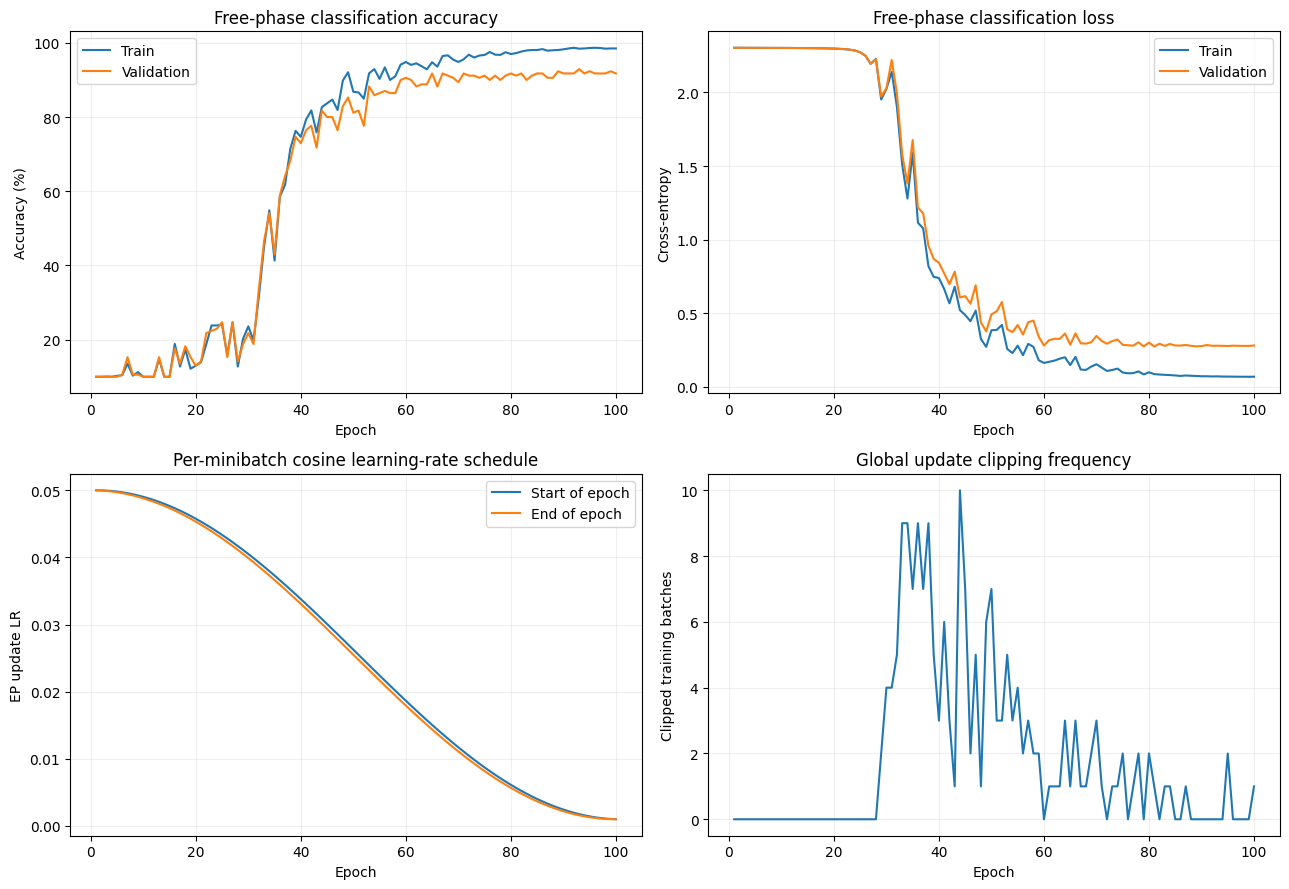

Best epoch 93 | Val 92.94% | CE 0.2800
Reference fixed-LR verification run: 92.94% best validation (compare only under identical protocol).


In [7]:
epochs = [h['epoch'] for h in history]
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
axs[0,0].plot(epochs, [h['train_accuracy'] for h in history], label='Train')
axs[0,0].plot(epochs, [h['val_accuracy'] for h in history], label='Validation')
axs[0,0].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Free-phase classification accuracy')
axs[0,0].legend(); axs[0,0].grid(alpha=0.2)
axs[0,1].plot(epochs, [h['train_ce'] for h in history], label='Train')
axs[0,1].plot(epochs, [h['val_ce'] for h in history], label='Validation')
axs[0,1].set(xlabel='Epoch', ylabel='Cross-entropy', title='Free-phase classification loss')
axs[0,1].legend(); axs[0,1].grid(alpha=0.2)
axs[1,0].plot(epochs, [h['lr_start'] for h in history], label='Start of epoch')
axs[1,0].plot(epochs, [h['lr_end'] for h in history], label='End of epoch')
axs[1,0].set(xlabel='Epoch', ylabel='EP update LR', title='Per-minibatch cosine learning-rate schedule')
axs[1,0].legend(); axs[1,0].grid(alpha=0.2)
axs[1,1].plot(epochs, [h['clipped_batches'] for h in history])
axs[1,1].set(xlabel='Epoch', ylabel='Clipped training batches', title='Global update clipping frequency')
axs[1,1].grid(alpha=0.2)
plt.tight_layout(); plt.show()

best_record = next(h for h in history if h['epoch'] == best_epoch)
print(f'Best epoch {best_epoch} | Val {best_record["val_accuracy"]:.2f}% | CE {best_record["val_ce"]:.4f}')
print('Reference fixed-LR verification run: 92.94% best validation (compare only under identical protocol).')


## 7. Best-checkpoint nudging and local learning audit

In [8]:
@torch.no_grad()
def ep_learning_audit(model, loader, sample_count=4):
    x,y=next(iter(loader)); x=x[:sample_count].to(DEVICE);y=y[:sample_count].to(DEVICE)
    free=model.feedforward_states(x)
    plus=model.nudged_states(x,y,+BETA,NUDGE_STEPS)
    minus=model.nudged_states(x,y,-BETA,NUDGE_STEPS)
    for name,s in [('free',free),('positive nudge',plus),('negative nudge',minus)]:
        losses,ce,total=model.energy_parts(x,s,y,+BETA if name=='positive nudge' else -BETA if name=='negative nudge' else 0.0)
        print(name,'| prediction loss by layer:',[round(float(v),6) for v in losses],'| nudging cost:',round(float(ce),6),'| total F:',round(float(total),6))
    print('State response to positive vs negative nudging:')
    for i,(p,m) in enumerate(zip(plus,minus),1):
        print(f' Level {i}: RMS separation={float((p-m).square().mean().sqrt()):.8f}')
    updates,_,_=model.centered_updates(x,y,BETA,NUDGE_STEPS)
    print('Centered local update norms:',{f'conv{i+1}':round(float(updates[f"bottom_weights.{i}"].norm()),7) for i in range(4)})

ep_learning_audit(model,val_loader)


free | prediction loss by layer: [0.0, 0.0, 0.0, 0.0, 0.0] | nudging cost: 0.008149 | total F: 0.0
positive nudge | prediction loss by layer: [0.0, 0.0, 0.0, 0.0, 0.0] | nudging cost: 0.008137 | total F: 0.000407
negative nudge | prediction loss by layer: [0.0, 0.0, 0.0, 0.0, 0.0] | nudging cost: 0.008161 | total F: -0.000408
State response to positive vs negative nudging:
 Level 1: RMS separation=0.00001240
 Level 2: RMS separation=0.00005675
 Level 3: RMS separation=0.00016694
 Level 4: RMS separation=0.00017119
 Level 5: RMS separation=0.00064744
Centered local update norms: {'conv1': 0.0269815, 'conv2': 0.0868875, 'conv3': 0.2223406, 'conv4': 0.4398573}


In [11]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in val_loader:
        pred = model.predict(x.to(DEVICE)).argmax(dim=1)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())

classes = list(range(10))
cm = confusion_matrix(y_true, y_pred, labels=classes)

print("CONFUSION MATRIX")
display(pd.DataFrame(cm, index=classes, columns=classes))

print("\nCLASS-WISE METRICS")
report = classification_report(y_true, y_pred, labels=classes, output_dict=True, zero_division=0)
metrics = pd.DataFrame(report).T.iloc[:10][["precision", "recall", "f1-score", "support"]]
metrics["accuracy (%)"] = np.divide(cm.diagonal(), cm.sum(axis=1), out=np.zeros(10, dtype=float),
                                    where=cm.sum(axis=1) > 0) * 100
display(metrics.round(3))

print(f"Overall Accuracy: {100 * np.trace(cm) / cm.sum():.2f}%")

CONFUSION MATRIX


,0,1,2,3,4,5,6,7,8,9
0,17,0,0,0,0,0,0,0,0,0
1,0,17,0,0,0,0,0,0,0,0
2,1,0,15,1,0,0,0,0,0,0
3,0,0,0,14,0,1,0,0,1,1
4,0,0,0,0,17,0,0,0,0,0
5,0,0,0,0,0,17,0,0,0,0
6,0,0,0,0,0,0,17,0,0,0
7,0,0,0,2,0,0,0,15,0,0
8,0,0,0,1,0,0,0,0,15,1
9,1,0,0,0,0,1,0,1,0,14



CLASS-WISE METRICS


,precision,recall,f1-score,support,accuracy (%)
0,0.895,1.000,0.944,17.0,100.000
1,1.000,1.000,1.000,17.0,100.000
2,1.000,0.882,0.938,17.0,88.235
3,0.778,0.824,0.800,17.0,82.353
4,1.000,1.000,1.000,17.0,100.000
5,0.895,1.000,0.944,17.0,100.000
6,1.000,1.000,1.000,17.0,100.000
7,0.938,0.882,0.909,17.0,88.235
8,0.938,0.882,0.909,17.0,88.235
9,0.875,0.824,0.848,17.0,82.353


Overall Accuracy: 92.94%
